# 01 · Data exploration (Olist)

*Demonstration project using public data (Olist). Not affiliated with any employer.*

Goal: understand the data before forecasting it. What does revenue look like over time, how much history is
usable, and how is revenue spread across markets and categories?

Definitions (from `src/prepare.py`): **revenue** = item price on `delivered` orders, by purchase month
(freight excluded). **GMV** = price + freight, a reference only. **Customer** = `customer_unique_id`.
All tables are built by `python -m src.prepare`; this notebook only reads and plots them.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from src import config as cfg, prepare

P = cfg.PROCESSED_DIR
total = pd.read_csv(P / "monthly_total.csv")
market = pd.read_csv(P / "monthly_market.csv")
category = pd.read_csv(P / "monthly_category.csv")
status = pd.read_csv(P / "order_status_by_month.csv")
outliers = pd.read_csv(P / "order_outliers.csv")
dq = json.loads((P / "data_quality.json").read_text())
for df in (total, market, category):
    df["month"] = pd.PeriodIndex(df["month"], freq="M").to_timestamp()

# Chart style: reference palette, recessive grid, thin lines, no dual axes.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.labelcolor": INK2, "xtick.color": MUTED,
    "ytick.color": MUTED, "text.color": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
    "font.family": ["Segoe UI", "DejaVu Sans"],
})
IMG = cfg.IMAGES_DIR
brl_m = mtick.FuncFormatter(lambda v, _: f"R$ {v/1e6:.1f}M")
pct = mtick.PercentFormatter(1.0, decimals=0)

## 1. Data quality

Checks run in `src/prepare.py` and saved to `data/processed/data_quality.json`.

In [2]:
q = {k: dq[k] for k in [
    "duplicate_order_ids", "duplicate_item_keys", "orders_excluded_not_delivered",
    "delivered_orders_without_delivery_date", "delivered_orders_without_items",
    "products_missing_category", "payments_vs_items_gap_over_1brl_share",
    "delivered_orders_before_model_window", "delivered_orders_after_model_window"]}
pd.Series(q, name="value").to_frame()

,value
duplicate_order_ids,0.0000
duplicate_item_keys,0.0000
orders_excluded_not_delivered,2963.0000
delivered_orders_without_delivery_date,8.0000
delivered_orders_without_items,0.0000
products_missing_category,610.0000
payments_vs_items_gap_over_1brl_share,0.0025
delivered_orders_before_model_window,267.0000
delivered_orders_after_model_window,0.0000


In [3]:
print("Order status counts (all purchase months):")
s = pd.Series(dq["order_status_counts"])
display(pd.DataFrame({"orders": s, "share": (s / s.sum()).round(4)}))

Order status counts (all purchase months):


,orders,share
delivered,96478,0.9702
shipped,1107,0.0111
canceled,625,0.0063
unavailable,609,0.0061
invoiced,314,0.0032
processing,301,0.0030
created,5,0.0001
approved,2,0.0000


**Which months are usable?** Delivered orders by purchase month. Months under 500 delivered orders are flagged
as sparse. Olist's data starts with a handful of test-like orders in late 2016, and the snapshot ends in
Sep–Oct 2018 with only a few orders, none of them with status `delivered`.

In [4]:
cols = ["month", "delivered", "canceled", "unavailable", "shipped", "total", "delivered_share", "sparse_flag"]
status[[c for c in cols if c in status.columns]]

,month,delivered,canceled,unavailable,shipped,total,delivered_share,sparse_flag
0,2016-09,1,2,0,1,4,0.2500,True
1,2016-10,265,24,7,8,324,0.8179,True
2,2016-12,1,0,0,0,1,1.0000,True
3,2017-01,750,3,10,16,800,0.9375,False
4,2017-02,1653,17,45,21,1780,0.9287,False
5,2017-03,2546,33,32,45,2682,0.9493,False
6,2017-04,2303,18,9,49,2404,0.9580,False
7,2017-05,3546,29,31,55,3700,0.9584,False
8,2017-06,3135,16,24,47,3245,0.9661,False
9,2017-07,3872,28,52,56,4026,0.9617,False


**Outliers.** Orders above the 99.9th percentile of order revenue. They look like genuine large baskets
(several units of the same product, or single high-price items), not data errors, so they are **kept**.

In [5]:
print(f"Flagged orders: {len(outliers)}  (threshold R$ {outliers['threshold'].iloc[0]:,.0f}); "
      f"their share of model-window revenue: {outliers['revenue'].sum() / dq['model_window_revenue']:.2%}")
outliers.head(10)

Flagged orders: 96  (threshold R$ 2,258); their share of model-window revenue: 2.38%


,order_id,month,market,revenue,items,max_item_price,category,threshold
0,03caa2c082116e1d31e67e9ae3700499,2017-09,RJ,13440.0,8,1680.0,Other,2258.0
1,736e1922ae60d0d6a89247b851902527,2018-07,Rest of Brazil,7160.0,4,1790.0,Other,2258.0
2,0812eb902a67711a1cb742b3cdaa65ae,2017-02,Rest of Brazil,6735.0,1,6735.0,housewares,2258.0
3,fefacc66af859508bf1a7934eab1e97f,2018-07,Rest of Brazil,6729.0,1,6729.0,Other,2258.0
4,f5136e38d1a14a4dbd87dff67da82701,2017-05,SP,6499.0,1,6499.0,Other,2258.0
5,2cc9089445046817a7539d90805e6e5a,2017-11,MG,5934.6,6,989.1,Other,2258.0
6,a96610ab360d42a2e5335a3998b4718a,2017-04,RJ,4799.0,1,4799.0,Other,2258.0
7,199af31afc78c699f0dbf71fb178d4d4,2017-04,SP,4690.0,1,4690.0,Other,2258.0
8,8dbc85d1447242f3b127dda390d56e19,2018-06,Rest of Brazil,4590.0,1,4590.0,Other,2258.0
9,d2f270487125ddc41fd134c4003ad1d7,2018-05,RJ,4400.0,2,2200.0,watches_gifts,2258.0


**Handling decisions**

| Issue | Decision |
|---|---|
| Non-delivered orders (canceled, unavailable, shipped, invoiced, …) | Counted above, excluded from revenue |
| Sparse months (2016, Sep–Oct 2018) | Kept in tidy tables with `in_model_window = False`; trimmed from modelling |
| Delivered orders with no delivery date | Kept: status says delivered and items exist |
| Products with no category | Labelled `unknown`, rolled into "Other" |
| Two untranslated categories | Portuguese name kept |
| Payments ≠ items + freight on a few orders | Not used: revenue comes from item prices, payments only cross-checked |
| Large orders | Flagged, kept |

## 2. Revenue over time

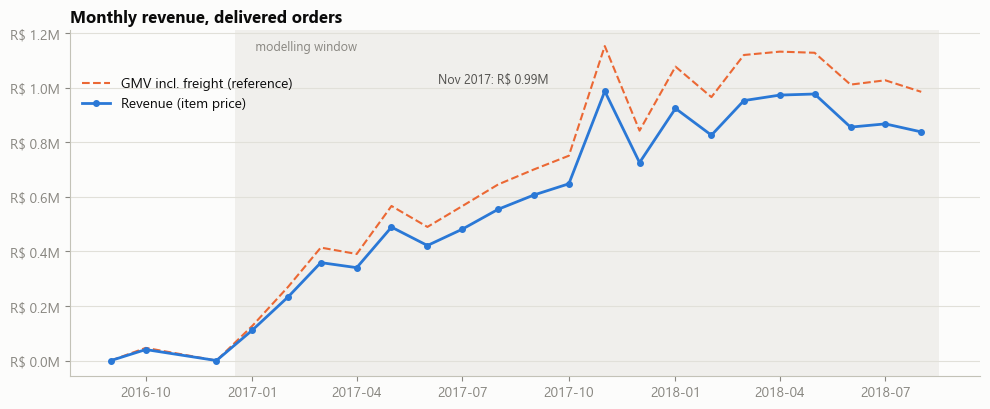

In [6]:
w = total[total["in_model_window"]]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.axvspan(w["month"].min() - pd.Timedelta(days=15), w["month"].max() + pd.Timedelta(days=15),
           color="#f0efec", zorder=0, lw=0)
ax.plot(total["month"], total["gmv"], color=SERIES[1], lw=1.5, ls="--", label="GMV incl. freight (reference)")
ax.plot(total["month"], total["revenue"], color=SERIES[0], marker="o", ms=4, label="Revenue (item price)")
ax.yaxis.set_major_formatter(brl_m)
ax.set_title("Monthly revenue, delivered orders")
ax.text(w["month"].min(), ax.get_ylim()[1] * 0.97, " modelling window", color=MUTED, va="top", fontsize=9)
pk = w.loc[w["revenue"].idxmax()]
ax.annotate(f"{pk['month']:%b %Y}: R$ {pk['revenue']/1e6:.2f}M", (pk["month"], pk["revenue"]),
            xytext=(-120, 6), textcoords="offset points", color=INK2, fontsize=9)
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.9))
fig.tight_layout(); fig.savefig(IMG / "01_monthly_revenue.png", dpi=150); plt.show()

In [7]:
h17 = w[(w["month"] >= "2017-01-01") & (w["month"] <= "2017-08-01")]["revenue"].sum()
h18 = w[(w["month"] >= "2018-01-01") & (w["month"] <= "2018-08-01")]["revenue"].sum()
last6 = w.tail(6)
nov = w.loc[w["month"] == "2017-11-01", "revenue"].iloc[0]
octo = w.loc[w["month"] == "2017-10-01", "revenue"].iloc[0]
dec = w.loc[w["month"] == "2017-12-01", "revenue"].iloc[0]
print(f"Model window: {dq['model_window_months']} months, revenue R$ {dq['model_window_revenue']/1e6:.2f}M "
      f"(GMV R$ {dq['model_window_gmv']/1e6:.2f}M; freight = {1 - dq['model_window_revenue']/dq['model_window_gmv']:.1%} of GMV)")
print(f"Jan-Aug 2018 vs Jan-Aug 2017 revenue: {h18/h17 - 1:+.0%}")
print(f"Last 6 months (Mar-Aug 2018): mean R$ {last6['revenue'].mean()/1e6:.2f}M/month, "
      f"min {last6['revenue'].min()/1e6:.2f}M, max {last6['revenue'].max()/1e6:.2f}M")
print(f"Nov 2017 (Black Friday) vs Oct 2017: {nov/octo - 1:+.0%}; Dec 2017 vs Oct 2017: {dec/octo - 1:+.0%}")

Model window: 20 months, revenue R$ 13.18M (GMV R$ 15.37M; freight = 14.3% of GMV)
Jan-Aug 2018 vs Jan-Aug 2017 revenue: +141%
Last 6 months (Mar-Aug 2018): mean R$ 0.91M/month, min 0.84M, max 0.98M
Nov 2017 (Black Friday) vs Oct 2017: +52%; Dec 2017 vs Oct 2017: +12%


## 3. Drivers: customers, orders per customer, order value

Revenue = customers × orders per customer × AOV. Each driver on its own chart (different units).

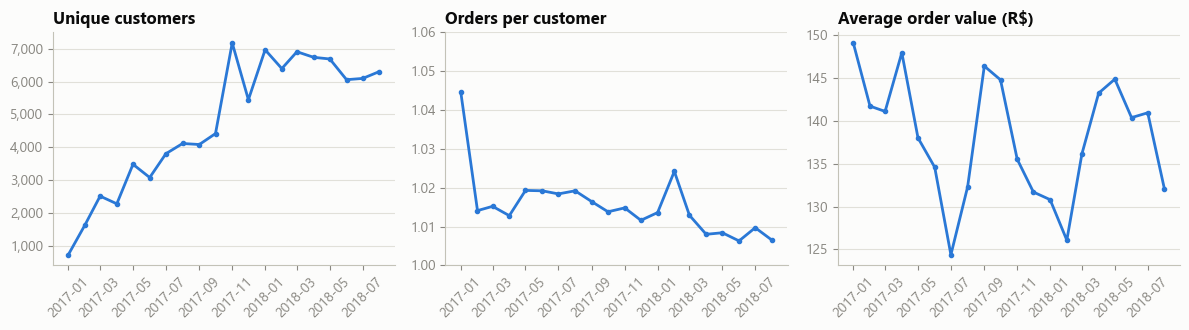

Repeat rate in window (customers with 2+ delivered orders): 3.0%; orders per customer over the whole window: 1.033
AOV range: R$ 124 - 149; customer growth Aug 2018 vs Jan 2017: 8.8x


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col, title, fmt in [
    (axes[0], "customers", "Unique customers", mtick.StrMethodFormatter("{x:,.0f}")),
    (axes[1], "orders_per_customer", "Orders per customer", mtick.StrMethodFormatter("{x:.2f}")),
    (axes[2], "aov", "Average order value (R$)", mtick.StrMethodFormatter("{x:,.0f}")),
]:
    ax.plot(w["month"], w[col], color=SERIES[0], marker="o", ms=3)
    ax.set_title(title); ax.yaxis.set_major_formatter(fmt)
    ax.tick_params(axis="x", labelrotation=45)
axes[1].set_ylim(1.0, 1.06)
fig.tight_layout(); fig.savefig(IMG / "01_drivers.png", dpi=150); plt.show()
print(f"Repeat rate in window (customers with 2+ delivered orders): {dq['repeat_rate_model_window']:.1%}; "
      f"orders per customer over the whole window: {dq['orders_per_customer_model_window']:.3f}")
print(f"AOV range: R$ {w['aov'].min():.0f} - {w['aov'].max():.0f}; "
      f"customer growth Aug 2018 vs Jan 2017: {w['customers'].iloc[-1]/w['customers'].iloc[0]:.1f}x")

## 4. Seasonality

Only 20 clean months, so each calendar month Jan–Aug appears twice and Sep–Dec once. That is not enough to
estimate yearly seasonality reliably. Growth and seasonality are also mixed together in 2017.

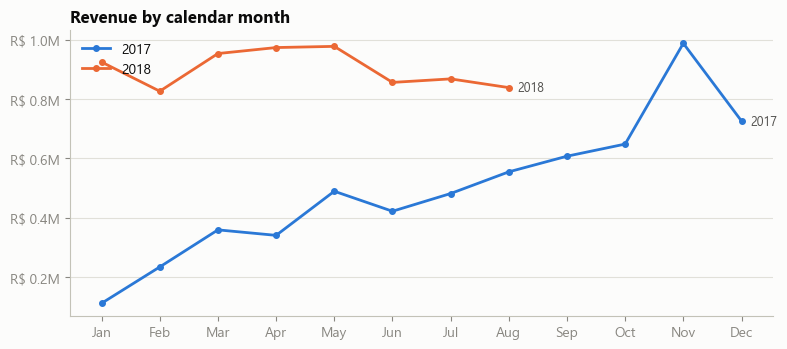

YoY growth by month (2018 vs 2017):
m
1    +727%
2    +253%
3    +165%
4    +186%
5    +100%
6    +103%
7     +80%
8     +51%


In [9]:
s = w.assign(year=w["month"].dt.year, m=w["month"].dt.month)
piv = s.pivot(index="m", columns="year", values="revenue")
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, y in enumerate(piv.columns):
    ax.plot(piv.index, piv[y], color=SERIES[i], marker="o", ms=4, label=str(y))
    last = piv[y].dropna()
    ax.text(last.index[-1] + 0.15, last.iloc[-1], str(y), color=INK2, va="center", fontsize=9)
ax.set_xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.yaxis.set_major_formatter(brl_m); ax.set_title("Revenue by calendar month"); ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig(IMG / "01_seasonality.png", dpi=150); plt.show()
print("YoY growth by month (2018 vs 2017):")
print((piv[2018] / piv[2017] - 1).dropna().map("{:+.0%}".format).to_string())

## 5. Market mix

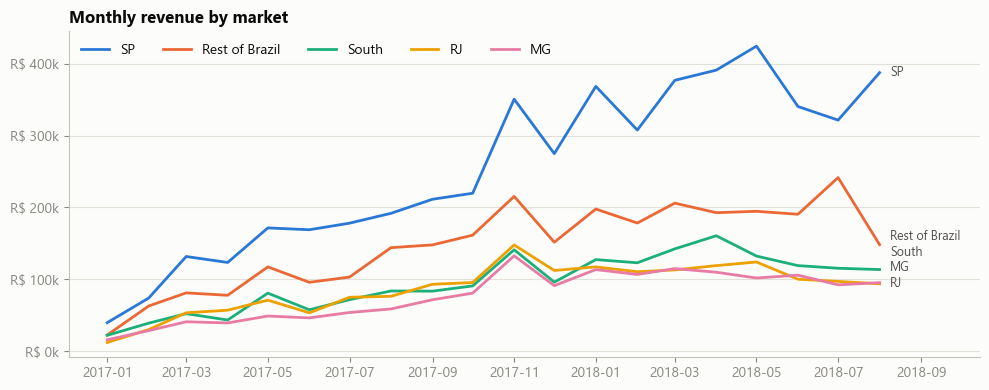

In [10]:
mk = market[market["in_model_window"]]
order = list(dq["market_revenue_share"].keys())
fig, ax = plt.subplots(figsize=(10, 4))
ends = {}
for i, m in enumerate(order):
    d = mk[mk["market"] == m]
    ax.plot(d["month"], d["revenue"], color=SERIES[i], label=m)
    ends[m] = d["revenue"].iloc[-1]
# direct labels, nudged apart so they never overlap
gap, prev = 22000, None
for m, y in sorted(ends.items(), key=lambda kv: kv[1]):
    y = y if prev is None else max(y, prev + gap)
    ax.text(mk["month"].max() + pd.Timedelta(days=8), y, m, color=INK2, va="center", fontsize=9)
    prev = y
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"R$ {v/1e3:.0f}k"))
ax.set_title("Monthly revenue by market"); ax.legend(loc="upper left", ncol=5)
ax.set_xlim(right=mk["month"].max() + pd.Timedelta(days=75))
fig.tight_layout(); fig.savefig(IMG / "01_market_revenue.png", dpi=150); plt.show()

In [11]:
def window_sum(df, key, a, b):
    x = df[(df["month"] >= a) & (df["month"] <= b)]
    return x.groupby(key)[["revenue", "orders", "customers"]].sum()
a = window_sum(market, "market", "2017-01-01", "2017-08-01")
b = window_sum(market, "market", "2018-01-01", "2018-08-01")
tot = mk.groupby("market")[["revenue", "orders", "customers"]].sum()
summary = pd.DataFrame({
    "revenue_R$M": (tot["revenue"] / 1e6).round(2),
    "share": (tot["revenue"] / tot["revenue"].sum()).round(3),
    "aov_R$": (tot["revenue"] / tot["orders"]).round(1),
    "yoy_jan_aug": (b["revenue"] / a["revenue"] - 1).round(3),
}).loc[order]
summary

,revenue_R$M,share,aov_R$,yoy_jan_aug
market,,,,
SP,5.06,0.384,125.1,1.705
Rest of Brazil,2.93,0.222,159.2,1.201
South,1.90,0.144,137.7,1.297
RJ,1.75,0.133,142.3,1.045
MG,1.55,0.117,136.8,1.531


**Concentration.** The top-5 states by revenue in the window:

In [12]:
print(f"Top 5 states {dq['top5_states']} = {dq['top5_state_revenue_share']:.1%} of revenue")

Top 5 states ['SP', 'RJ', 'MG', 'RS', 'PR'] = 73.9% of revenue


## 6. Category mix

Top 10 categories (`TOP_N_CATEGORIES` in `src/config.py`) by window revenue; everything else is "Other".

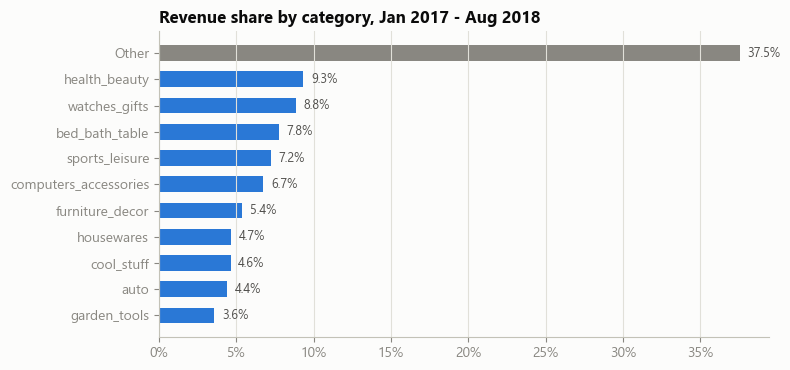

In [13]:
cs = pd.Series(dq["category_revenue_share"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(cs.index, cs.values, color=[MUTED if c == "Other" else SERIES[0] for c in cs.index], height=0.6)
for y, v in enumerate(cs.values):
    ax.text(v + 0.005, y, f"{v:.1%}", va="center", color=INK2, fontsize=9)
ax.xaxis.set_major_formatter(pct); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_title("Revenue share by category, Jan 2017 - Aug 2018")
fig.tight_layout(); fig.savefig(IMG / "01_category_share.png", dpi=150); plt.show()

In [14]:
ca = window_sum(category, "category", "2017-01-01", "2017-08-01")
cb = window_sum(category, "category", "2018-01-01", "2018-08-01")
ct = category[category["in_model_window"]].groupby("category")[["revenue", "orders"]].sum()
pd.DataFrame({
    "revenue_R$M": (ct["revenue"] / 1e6).round(2),
    "aov_R$": (ct["revenue"] / ct["orders"]).round(1),
    "yoy_jan_aug": (cb["revenue"] / ca["revenue"] - 1).round(3),
}).sort_values("revenue_R$M", ascending=False)

,revenue_R$M,aov_R$,yoy_jan_aug
category,,,
Other,4.95,134.8,1.440
health_beauty,1.23,142.8,2.103
watches_gifts,1.16,211.9,2.420
bed_bath_table,1.02,110.4,1.092
sports_leisure,0.95,126.8,1.386
computers_accessories,0.89,136.2,1.312
furniture_decor,0.71,112.9,1.234
cool_stuff,0.61,171.5,0.104
housewares,0.61,107.1,2.072


## 7. What this means for the forecast

In [15]:
print(f"- Usable history: {dq['model_window_months']} months ({cfg.MODEL_START} to {cfg.MODEL_END}).")
print(f"- Revenue grew {h18/h17 - 1:+.0%} Jan-Aug 2018 vs 2017, but the last 6 months are roughly flat "
      f"(R$ {last6['revenue'].min()/1e6:.2f}M-{last6['revenue'].max()/1e6:.2f}M). A trend model fit on all 20 months "
      f"may over-extrapolate 2017's growth.")
print(f"- Nov 2017 was {nov/octo - 1:+.0%} vs Oct (Black Friday). With one November in the data, the forecast "
      f"cannot learn this reliably; the Nov 2018 forecast needs an explicit judgement or caveat.")
print(f"- Repeat rate is {dq['repeat_rate_model_window']:.1%} (orders/customer {dq['orders_per_customer_model_window']:.3f}): "
      f"revenue ~ unique customers x AOV, as planned.")
print(f"- SP alone is {dq['market_revenue_share']['SP']:.0%} of revenue; top 5 states {dq['top5_state_revenue_share']:.0%}.")
print(f"- 'Other' is {dq['category_revenue_share']['Other']:.0%} of revenue: the category long tail is large.")

- Usable history: 20 months (2017-01 to 2018-08).
- Revenue grew +141% Jan-Aug 2018 vs 2017, but the last 6 months are roughly flat (R$ 0.84M-0.98M). A trend model fit on all 20 months may over-extrapolate 2017's growth.
- Nov 2017 was +52% vs Oct (Black Friday). With one November in the data, the forecast cannot learn this reliably; the Nov 2018 forecast needs an explicit judgement or caveat.
- Repeat rate is 3.0% (orders/customer 1.033): revenue ~ unique customers x AOV, as planned.
- SP alone is 38% of revenue; top 5 states 74%.
- 'Other' is 38% of revenue: the category long tail is large.
